In [6]:
%load_ext autoreload
%autoreload 2
import mask_functions as mf

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
mag_bin_args=[
    (4,1600,0.35,'Log'),
    (2,800,0.35,'Log'),
    (1,400,0.35,'Log'),
]
mag_cuts =[ # bin_int, cut_int, mag, mag_cut
    # (0,5,1.58489),
    # (0,6,1.58489),
    # (0,7,1.58489),
    # (0,0, 8,1.58489),
    (0,0, 8,1.5),
    (0,1, 10,0.5),
    (0,2, 11,0.5),

    (1,3, 12,0.5),
    (1,4, 13,0.5),
    (1,5, 14,0.5),

    (2,6, 15,0.5),
    (2,7, 16,0.5),
    (2,8, 17,0.5),
    (2,9, 18,0.5),
    (2,10, 19,0.4),
    (2,11, 20,0.3),
]

save_path = '/global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint2'

In [4]:
def anacal_pipeline(save_path, mag_bin_args, mag_cuts):
    mag_min_max = [(m - d, m + d) for _,_,m,d in mag_cuts]
    tract_list = mf.get_anacal_tracts()
    tract_ids_cut, monsters, star_randoms, tract_mask, footprint = mf.load_baseline(tract_list)
    metas = mf.load_anacal(tract_ids_cut, tract_mask, footprint)
    gal_randoms = mf.make_gal_randoms(metas, footprint, tract_mask, rand_per_arcmin2=50)
    re_weights = mf.make_star_randoms(monsters, star_randoms, mag_min_max, mag_cuts, mag_bin_args)
    mf.run_anacal_corrs(metas, monsters, gal_randoms, star_randoms, mag_cuts, mag_bin_args, re_weights, save_path)

In [8]:
mag_min_max = [(m - d, m + d) for _,_,m,d in mag_cuts]
tract_list = mf.get_anacal_tracts()

In [9]:
tract_ids_cut, monsters, star_randoms, tract_mask, footprint = mf.load_baseline(tract_list)

footprinted
820 tracts selected
566 tracts filtered
566 tracts stared


  0%|          | 0/566 [00:00<?, ?it/s]

len monster 6824508
len star randoms 28651606


In [10]:
metas = mf.load_anacal(tract_ids_cut, tract_mask, footprint)

  0%|          | 0/566 [00:00<?, ?it/s]

len anacal 21857018


22,221 pixels; native depth in 96.0%, max coarsening level 5
16,140 pixels in joint fit (logquad), dispersion phi = 0.995
  depth: n(m_med=23.34) = 6.98 sum(wsel)/arcmin^2, s = 0.257, c = -0.119
         psf: -0.0140 ± 0.0001 dex/σ (-3.18%/σ, -0.0093 dex/unit), r(depth) = -0.37
143,257,857 randoms, weights in [0.511, 1.354]
test2


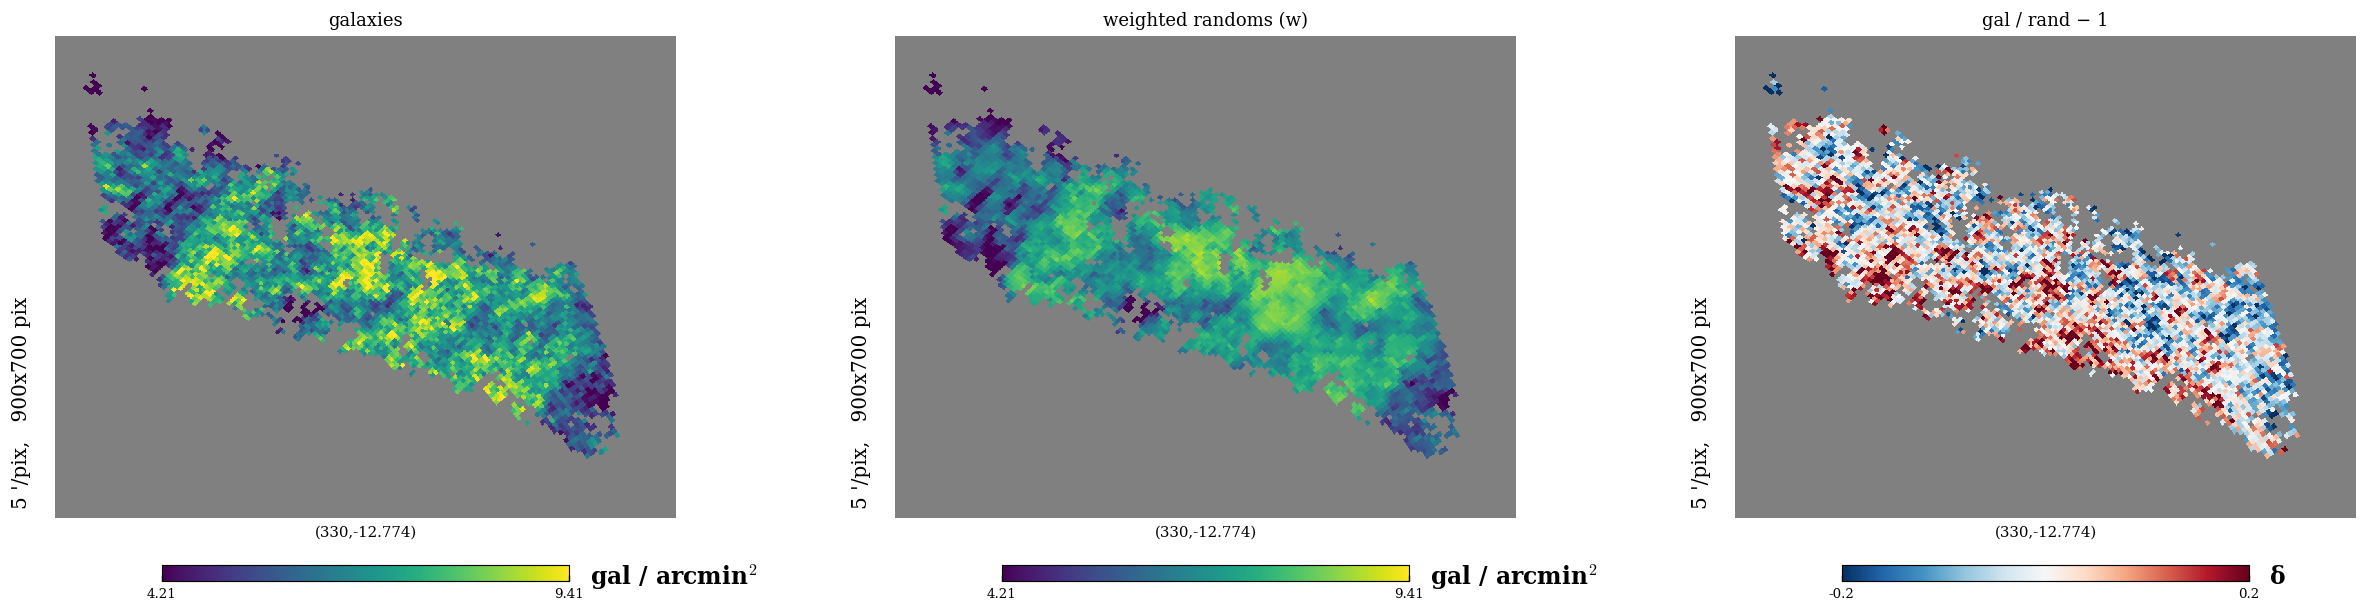

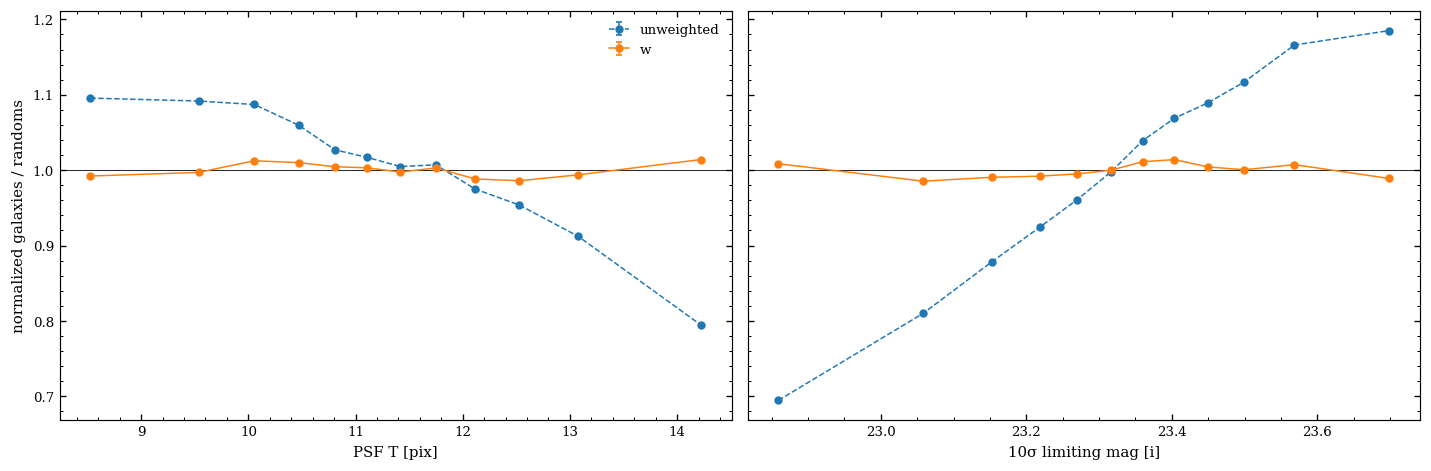

In [12]:
gal_randoms = mf.make_gal_randoms(metas, footprint, tract_mask, rand_per_arcmin2=50)

joint prior fit: converged=True, nll=-27318871.1


2026-11-12 13:45:10,111 - healpy - INFO - Sigma is 133.333333 arcmin (0.038785 rad) 
2026-11-12 13:45:10,112 - healpy - INFO - -> fwhm is 313.976006 arcmin
2026-11-12 13:45:10,114 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:45:10,114 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:45:10,556 - healpy - INFO - Sigma is 133.333333 arcmin (0.038785 rad) 
2026-11-12 13:45:10,556 - healpy - INFO - -> fwhm is 313.976006 arcmin
2026-11-12 13:45:10,558 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:45:10,558 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (6.5, 9.5]: 511 stars, σ = 133′ (θ_max = 26.7′), N_eff = 27, leak ≲ 3.7e-02


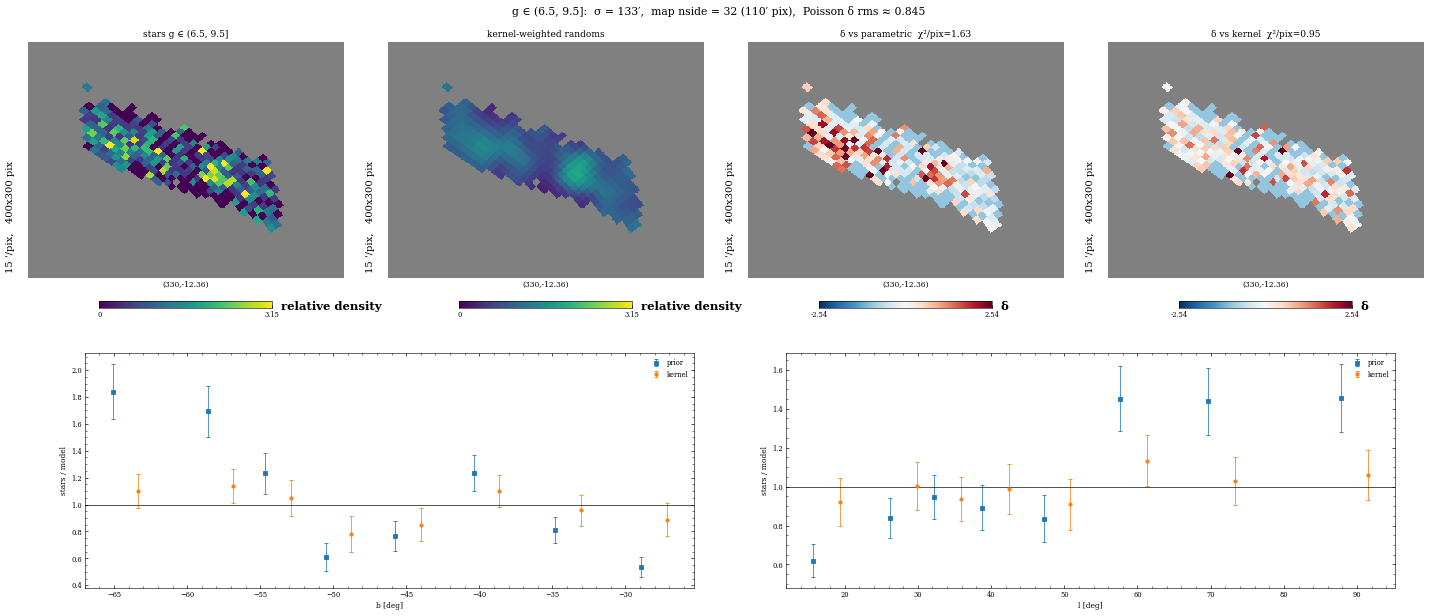

2026-11-12 13:45:22,875 - healpy - INFO - Sigma is 133.333333 arcmin (0.038785 rad) 
2026-11-12 13:45:22,876 - healpy - INFO - -> fwhm is 313.976006 arcmin
2026-11-12 13:45:22,877 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:45:22,878 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:45:23,327 - healpy - INFO - Sigma is 133.333333 arcmin (0.038785 rad) 
2026-11-12 13:45:23,328 - healpy - INFO - -> fwhm is 313.976006 arcmin
2026-11-12 13:45:23,329 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:45:23,329 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (9.5, 10.5]: 3,302 stars, σ = 133′ (θ_max = 26.7′), N_eff = 176, leak ≲ 5.7e-03


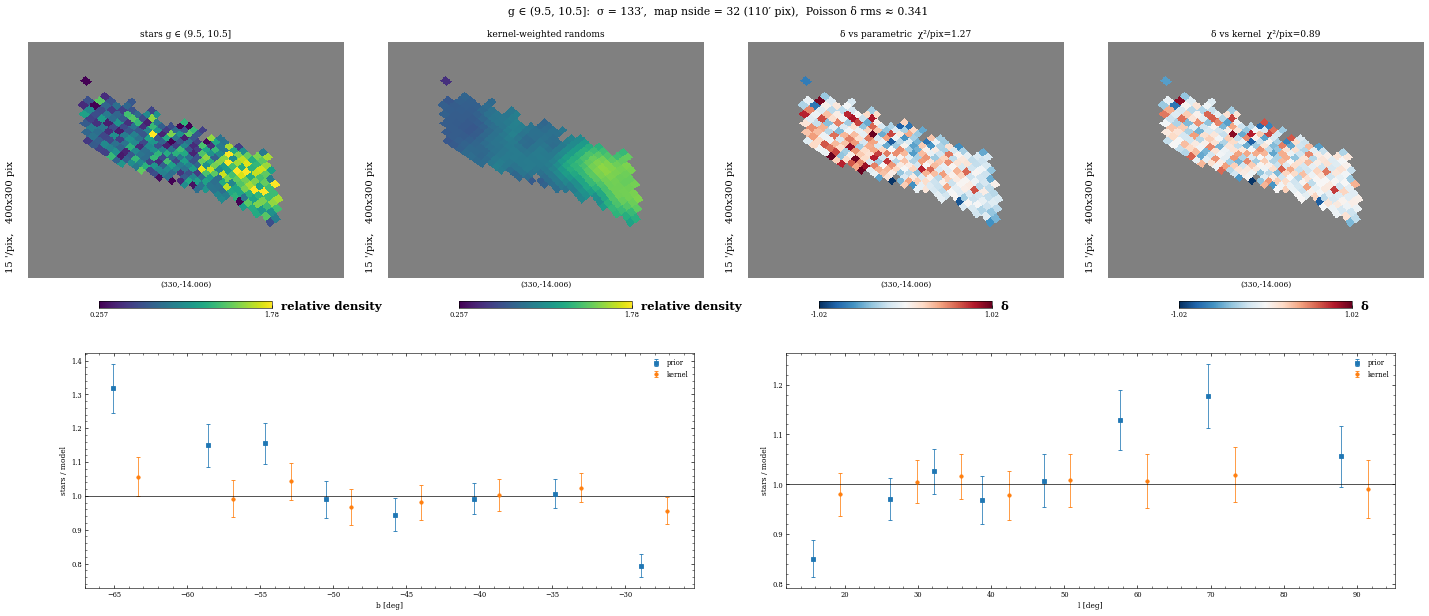

2026-11-12 13:45:36,426 - healpy - INFO - Sigma is 133.333333 arcmin (0.038785 rad) 
2026-11-12 13:45:36,427 - healpy - INFO - -> fwhm is 313.976006 arcmin
2026-11-12 13:45:36,428 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:45:36,428 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:45:36,877 - healpy - INFO - Sigma is 133.333333 arcmin (0.038785 rad) 
2026-11-12 13:45:36,878 - healpy - INFO - -> fwhm is 313.976006 arcmin
2026-11-12 13:45:36,879 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:45:36,879 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (10.5, 11.5]: 9,497 stars, σ = 133′ (θ_max = 26.7′), N_eff = 505, leak ≲ 2.0e-03


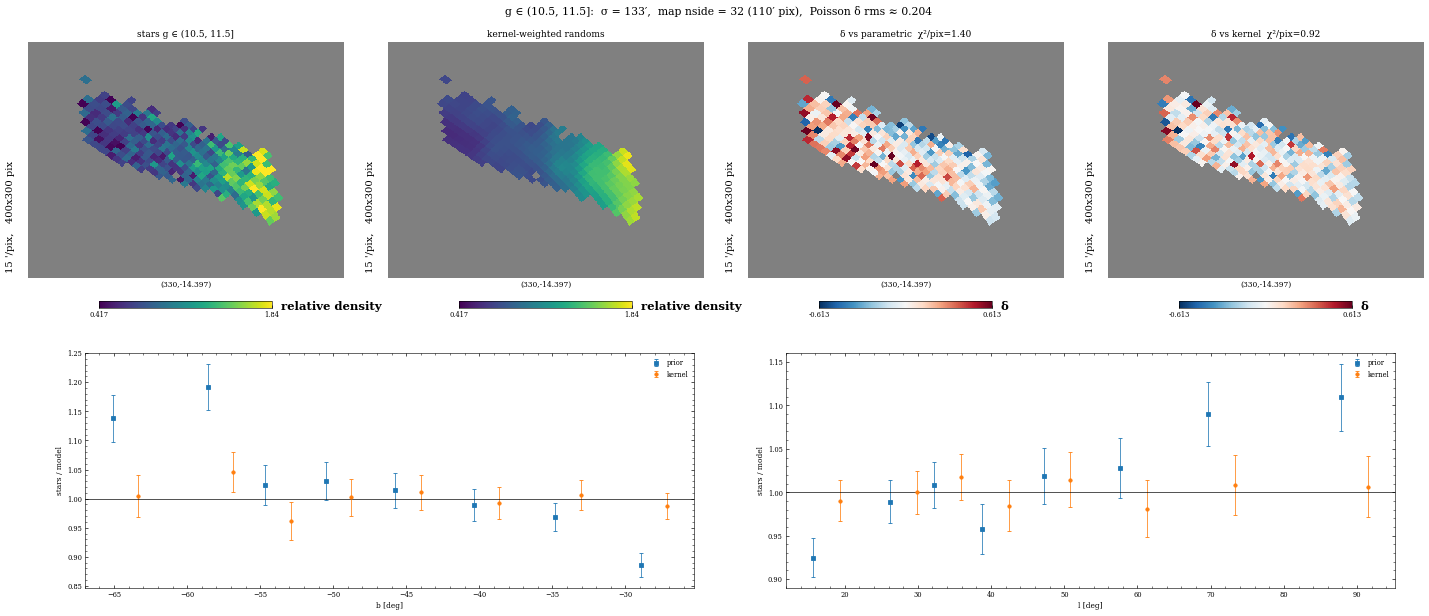

2026-11-12 13:45:49,417 - healpy - INFO - Sigma is 66.666667 arcmin (0.019393 rad) 
2026-11-12 13:45:49,418 - healpy - INFO - -> fwhm is 156.988003 arcmin
2026-11-12 13:45:49,419 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:45:49,420 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:45:49,867 - healpy - INFO - Sigma is 66.666667 arcmin (0.019393 rad) 
2026-11-12 13:45:49,867 - healpy - INFO - -> fwhm is 156.988003 arcmin
2026-11-12 13:45:49,869 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:45:49,869 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (11.5, 12.5]: 22,945 stars, σ = 67′ (θ_max = 13.3′), N_eff = 305, leak ≲ 3.3e-03


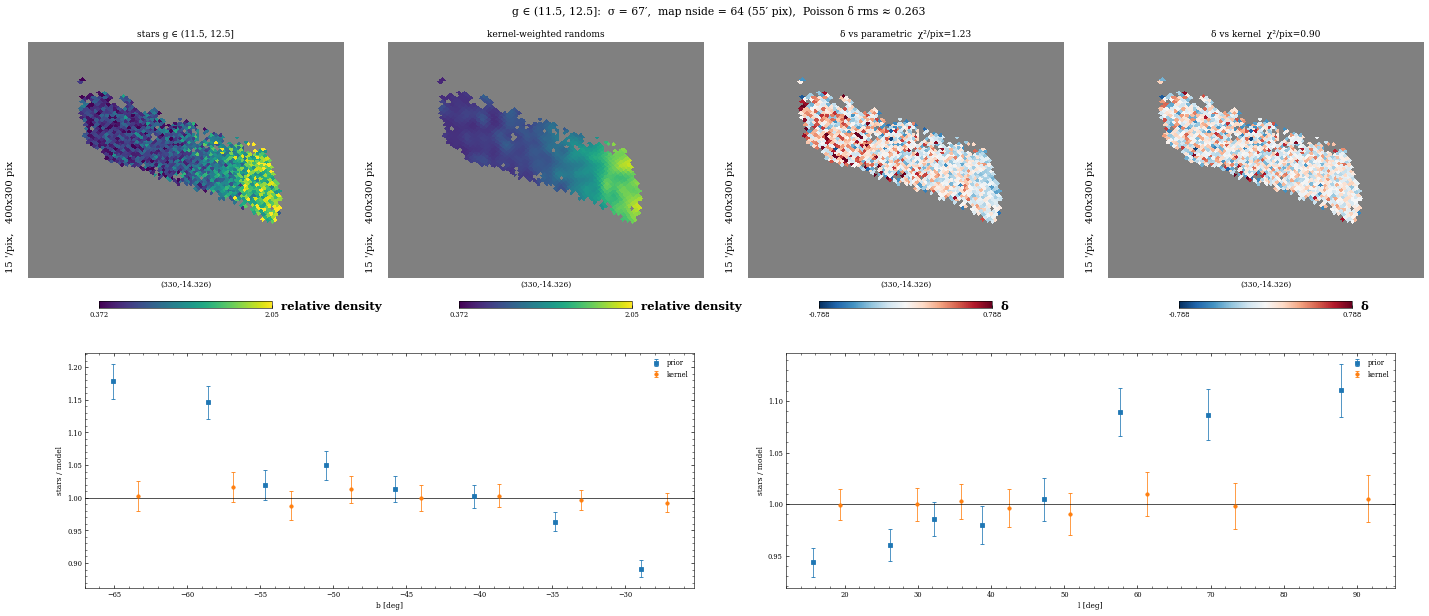

2026-11-12 13:46:02,474 - healpy - INFO - Sigma is 66.666667 arcmin (0.019393 rad) 
2026-11-12 13:46:02,476 - healpy - INFO - -> fwhm is 156.988003 arcmin
2026-11-12 13:46:02,477 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:02,477 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:46:02,936 - healpy - INFO - Sigma is 66.666667 arcmin (0.019393 rad) 
2026-11-12 13:46:02,936 - healpy - INFO - -> fwhm is 156.988003 arcmin
2026-11-12 13:46:02,937 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:02,938 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (12.5, 13.5]: 51,946 stars, σ = 67′ (θ_max = 13.3′), N_eff = 691, leak ≲ 1.4e-03


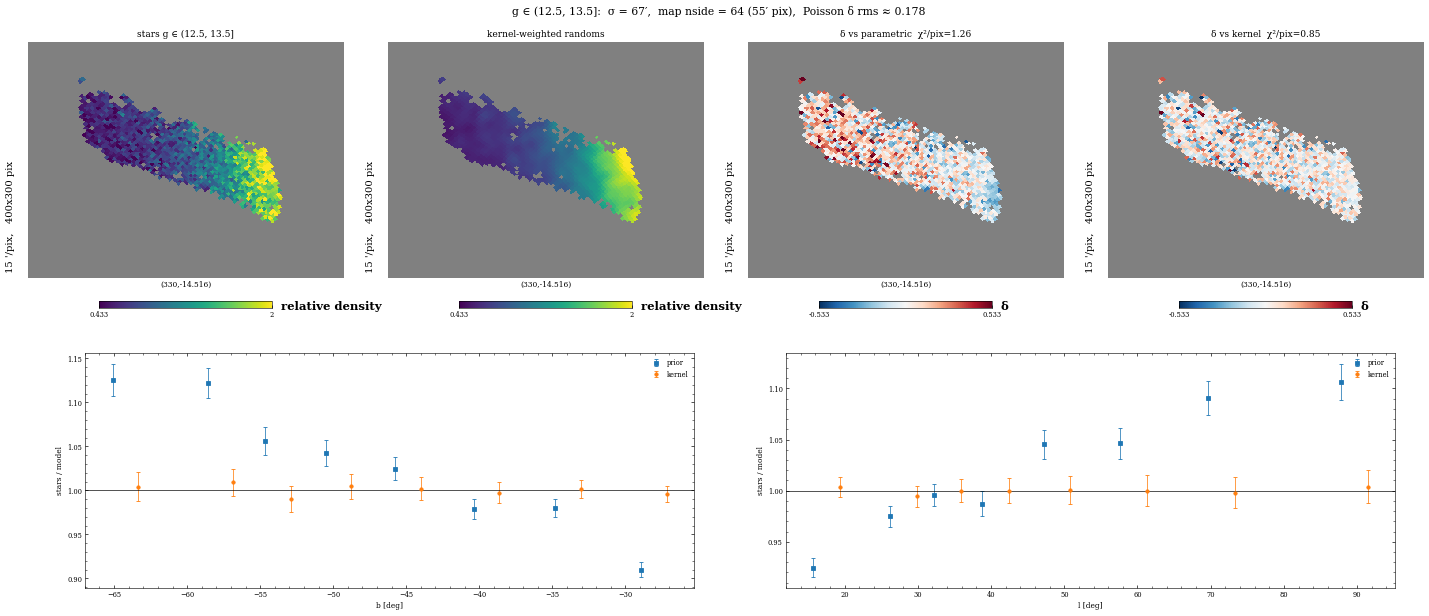

2026-11-12 13:46:15,252 - healpy - INFO - Sigma is 66.666667 arcmin (0.019393 rad) 
2026-11-12 13:46:15,254 - healpy - INFO - -> fwhm is 156.988003 arcmin
2026-11-12 13:46:15,255 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:15,255 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:46:15,699 - healpy - INFO - Sigma is 66.666667 arcmin (0.019393 rad) 
2026-11-12 13:46:15,699 - healpy - INFO - -> fwhm is 156.988003 arcmin
2026-11-12 13:46:15,700 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:15,701 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (13.5, 14.5]: 99,953 stars, σ = 67′ (θ_max = 13.3′), N_eff = 1,330, leak ≲ 7.5e-04


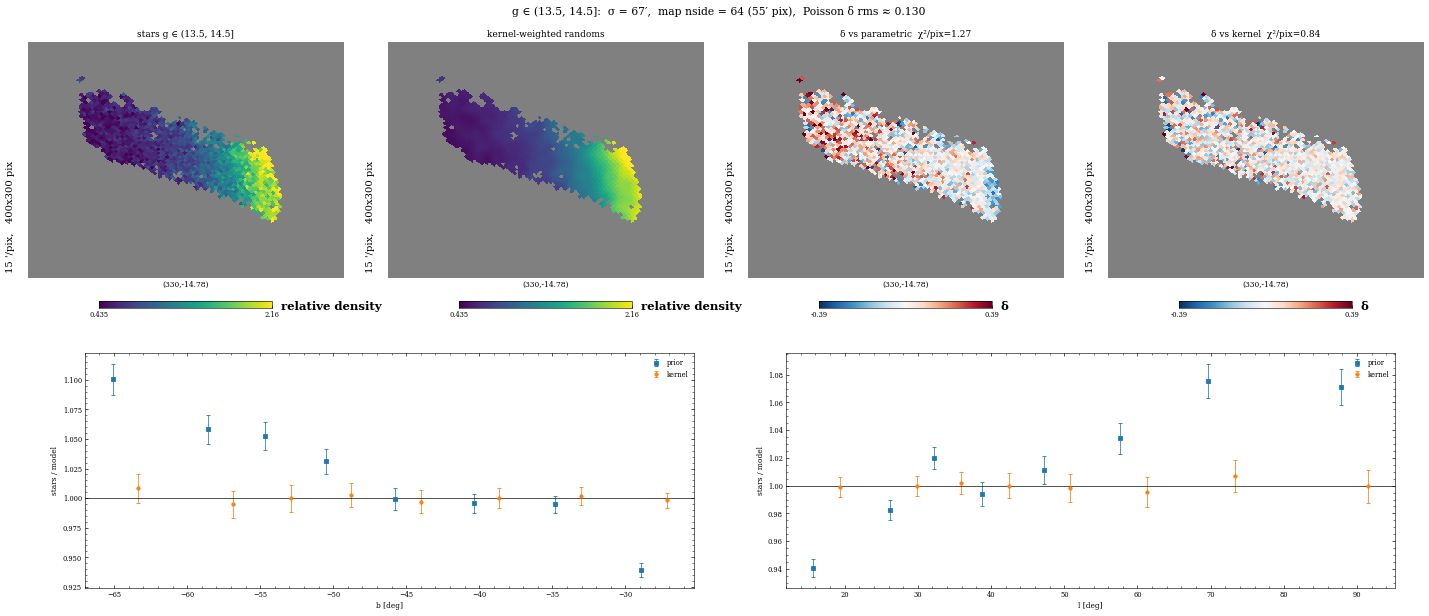

2026-11-12 13:46:28,080 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:46:28,080 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:46:28,082 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:28,082 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:46:28,545 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:46:28,546 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:46:28,548 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:28,548 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (14.5, 15.5]: 181,654 stars, σ = 33′ (θ_max = 6.7′), N_eff = 604, leak ≲ 1.7e-03


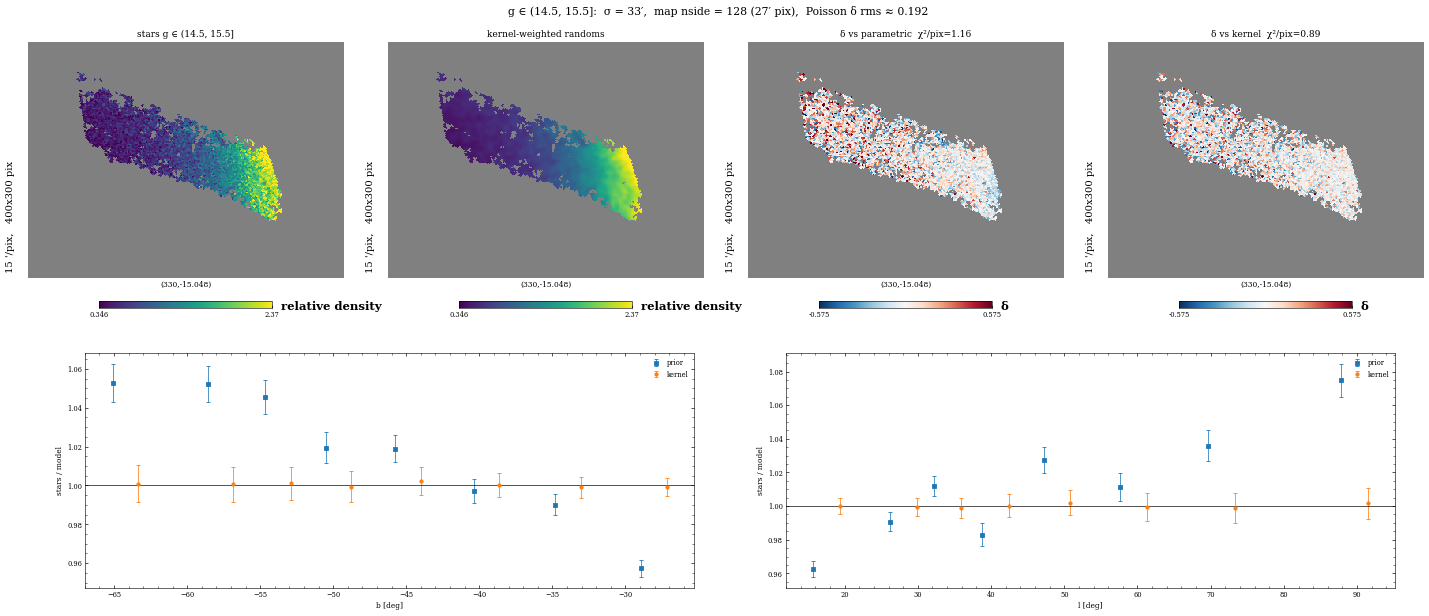

2026-11-12 13:46:41,375 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:46:41,376 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:46:41,378 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:41,378 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:46:41,822 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:46:41,823 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:46:41,825 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:41,825 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (15.5, 16.5]: 318,013 stars, σ = 33′ (θ_max = 6.7′), N_eff = 1,057, leak ≲ 9.5e-04


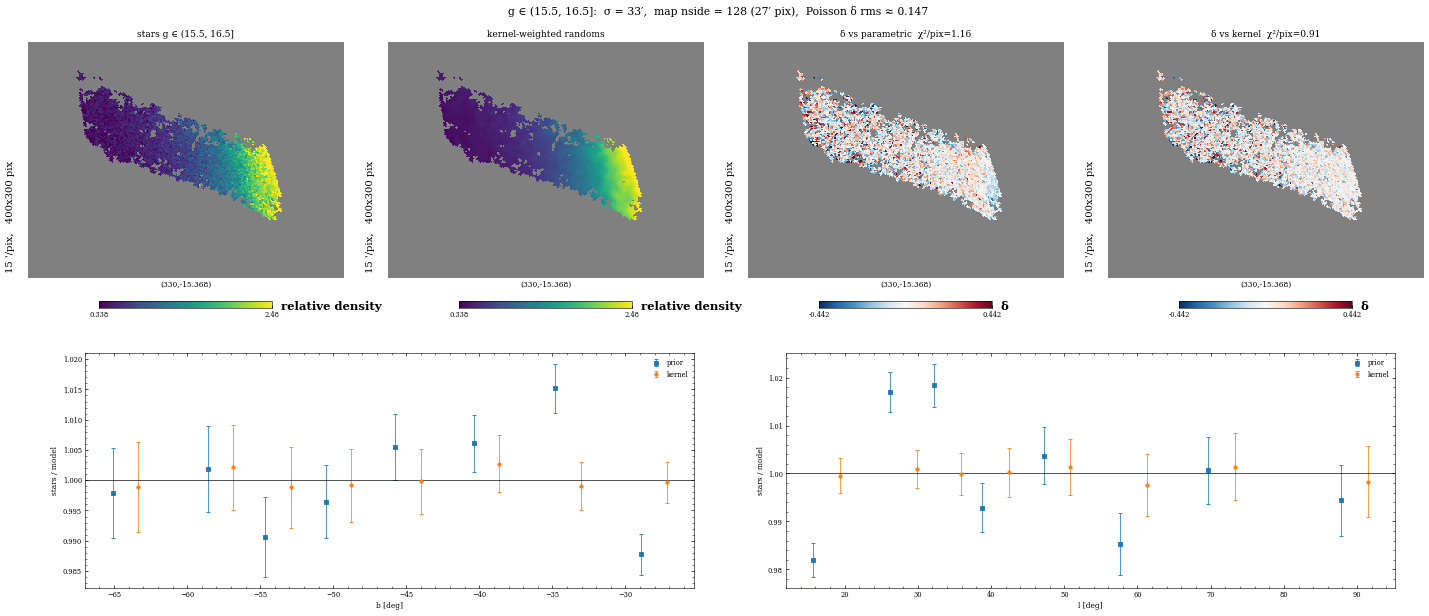

2026-11-12 13:46:54,203 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:46:54,204 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:46:54,205 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:54,205 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:46:54,650 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:46:54,651 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:46:54,652 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:46:54,653 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (16.5, 17.5]: 528,914 stars, σ = 33′ (θ_max = 6.7′), N_eff = 1,759, leak ≲ 5.7e-04


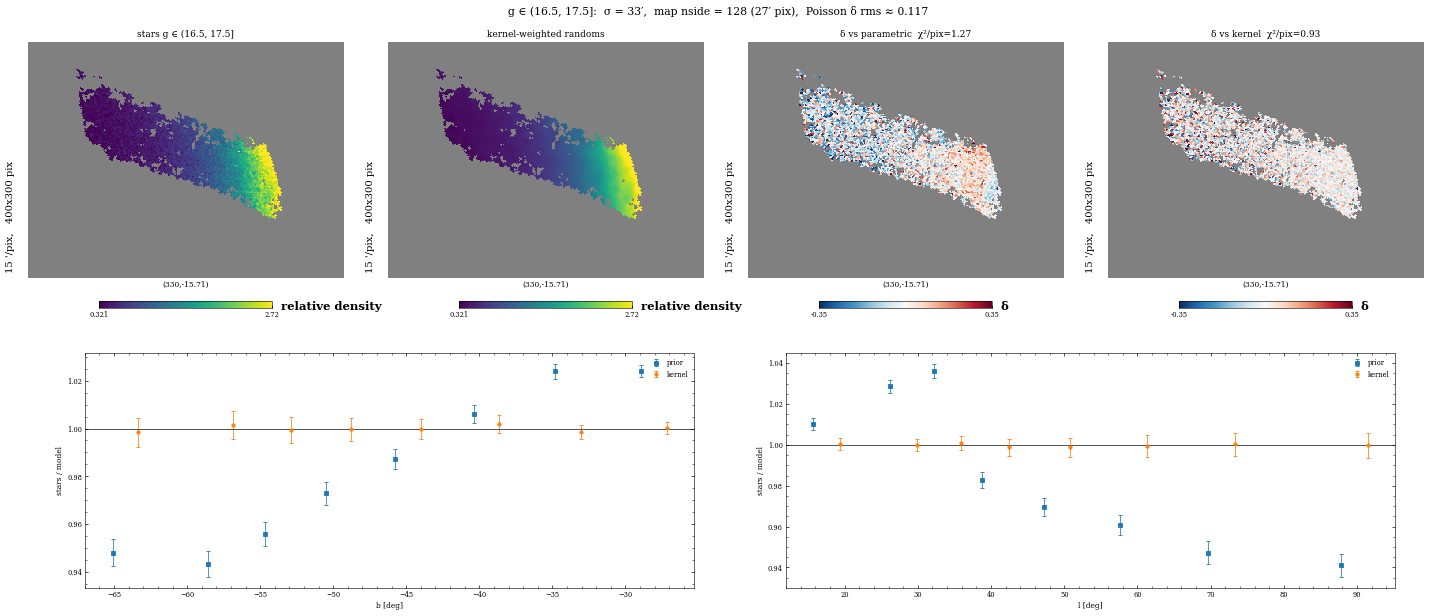

2026-11-12 13:47:07,093 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:47:07,094 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:47:07,095 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:47:07,096 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:47:07,539 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:47:07,539 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:47:07,541 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:47:07,541 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (17.5, 18.5]: 810,771 stars, σ = 33′ (θ_max = 6.7′), N_eff = 2,696, leak ≲ 3.7e-04


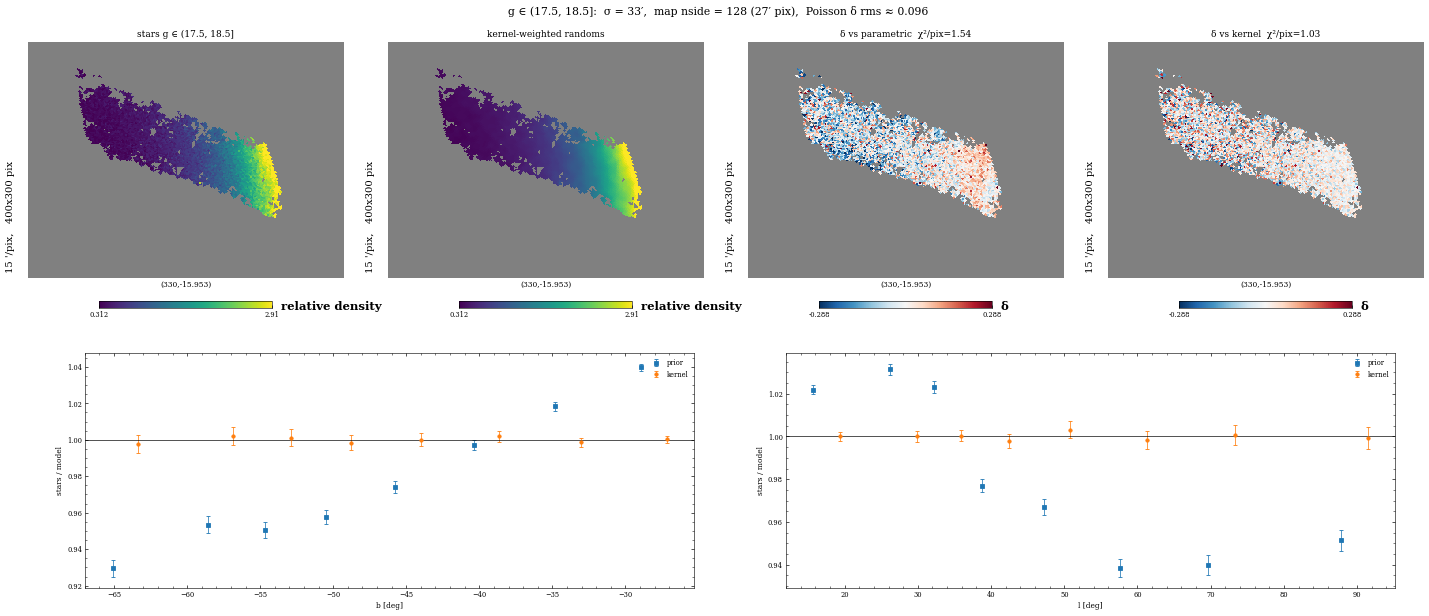

2026-11-12 13:47:20,025 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:47:20,027 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:47:20,028 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:47:20,028 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:47:20,472 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:47:20,473 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:47:20,474 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:47:20,475 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (18.6, 19.4]: 949,038 stars, σ = 33′ (θ_max = 6.7′), N_eff = 3,156, leak ≲ 3.2e-04


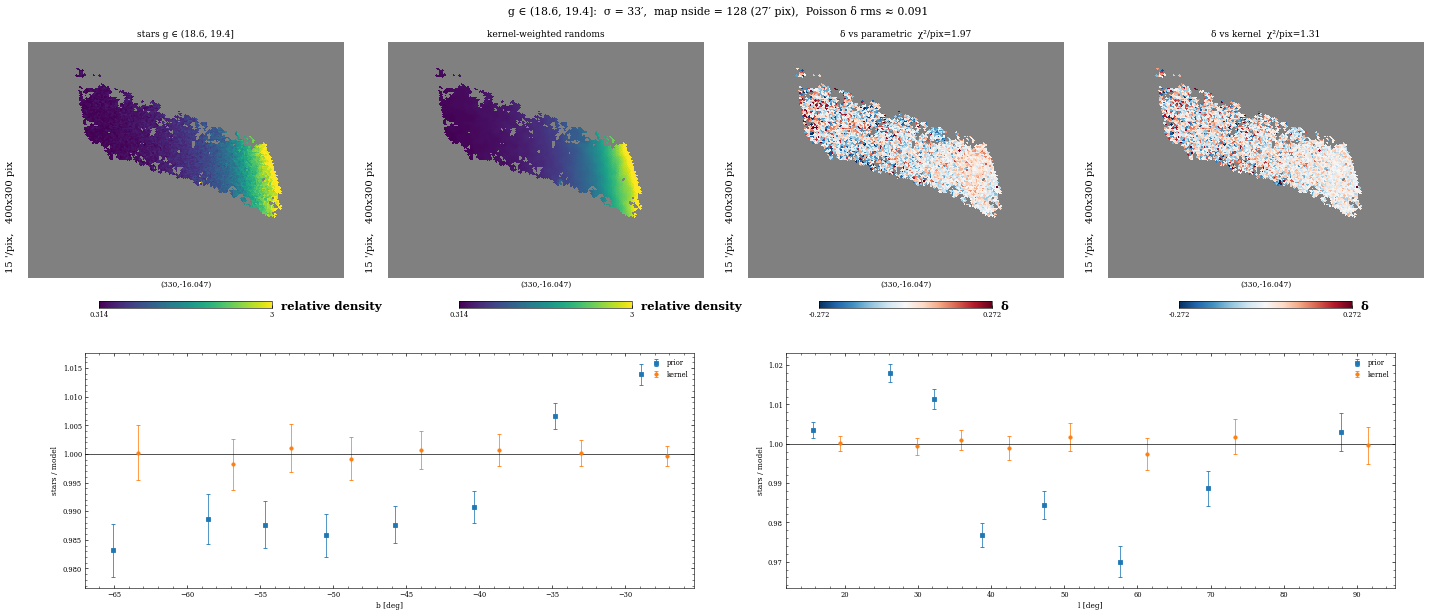

2026-11-12 13:47:33,534 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:47:33,535 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:47:33,536 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:47:33,536 - healpy - INFO - -> fwhm is 0.000000 arcmin
2026-11-12 13:47:33,981 - healpy - INFO - Sigma is 33.333333 arcmin (0.009696 rad) 
2026-11-12 13:47:33,982 - healpy - INFO - -> fwhm is 78.494002 arcmin
2026-11-12 13:47:33,983 - healpy - INFO - Sigma is 0.000000 arcmin (0.000000 rad) 
2026-11-12 13:47:33,983 - healpy - INFO - -> fwhm is 0.000000 arcmin


g ∈ (19.7, 20.3]: 1,052,162 stars, σ = 33′ (θ_max = 6.7′), N_eff = 3,499, leak ≲ 2.9e-04


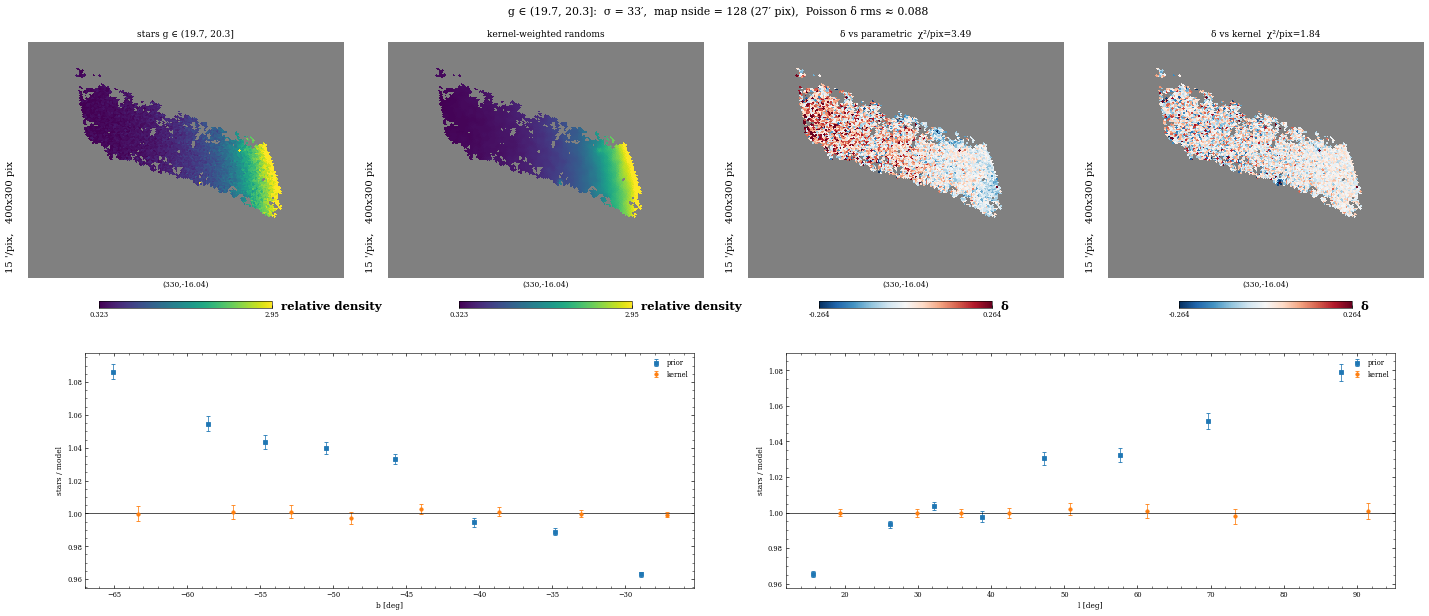

In [13]:
re_weights = mf.make_star_randoms(monsters, star_randoms, mag_min_max, mag_cuts, mag_bin_args)

In [ ]:
mf.run_anacal_corrs(metas, monsters, gal_randoms, star_randoms, mag_cuts, mag_bin_args, re_weights, save_path)

built gal


  0%|          | 0/12 [00:00<?, ?it/s]

meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint2/rand_g8.npz
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint2/rand_g10.npz
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint2/rand_g11.npz
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint2/rand_g12.npz
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint2/rand_g13.npz
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas randoms -> /global/homes/p/pladuca/desc-pladuca/dp2_masks/corr_ana_NNjoint2/rand_g14.npz
  done ng
  done R
  done flux
  done size
  done snr
  done nn
done nr
meas 

In [ ]:
def mdet_pipeline(save_path, mag_bin_args, mag_cuts):
    mag_min_max = [(m - d, m + d) for _,_,m,d in mag_cuts]

    tract_list = mf.get_mdet_tracts()

    tract_ids_cut, monsters, star_randoms, tract_mask, footprint = mf.load_baseline(tract_list)

    metas = mf.get_mdet_tracts(tract_ids_cut, tract_mask, footprint)

    gal_randoms = mf.make_gal_randoms(metas, footprint, tract_mask, rand_per_arcmin2=50,
                                      weight_col=None, snr_col='gauss_snr', mag_col='i_pgaussMag',
                                      psf_prefix='gauss_T', is_trace=True)

    re_weights = mf.make_star_randoms(monsters, star_randoms, mag_min_max, mag_cuts, mag_bin_args)

    mf.run_anacal_corrs(metas, monsters, gal_randoms, star_randoms, mag_cuts, mag_bin_args, re_weights, save_path)

def erin_pipeline(save_path, mag_bin_args, mag_cuts):
    mag_min_max = [(m - d, m + d) for _,_,m,d in mag_cuts]
    tract_list = mf.get_anacal_tracts()
    tract_ids_cut, monsters, star_randoms, tract_mask, footprint = mf.load_baseline(tract_list)
    metas = mf.load_anacal(tract_ids_cut, tract_mask, footprint)
    gal_randoms = mf.make_gal_randoms(metas, footprint, tract_mask, rand_per_arcmin2=50,
                                      weight_col=None, snr_col='s2n', mag_col='mag_i',
                                      psf_prefix='T', is_trace=True)
    re_weights = mf.make_star_randoms(monsters, star_randoms, mag_min_max, mag_cuts, mag_bin_args)
    mf.run_anacal_corrs(metas, monsters, gal_randoms, star_randoms, mag_cuts, mag_bin_args, re_weights, save_path)